# What is the probability that at least 2 balls are sunk in 100 or more games of pool with 1000 trials
X is the number of balls sunk each trial.
A trail would look like assume a player sinks 2 or more balls on break 2.5% of the time.

In [40]:
##Define the variables##
import math
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns

# Global setting to prevent font warnings on minus signs
plt.rcParams['axes.unicode_minus'] = False

# ==============================================================================
# PARAMETERS
# ==============================================================================
p_game_success = 0.025  # Player sinks >= 2 balls on break 2.5% of the time
num_games = 1_000       # 1,000 games per series
target_games = 100      # Target: 100 or more successful games
num_trials = 1_000      # 1,000 series trials


In [41]:
# 1. MATH stuffs
expected_successful_games = num_games * p_game_success  # 25 games

# Exact analytical calculation of P(Y >= 100) across 1,000 games
p_at_least_100_math = sum(
    math.comb(num_games, y) * (p_game_success ** y) * ((1 - p_game_success) ** (num_games - y))
    for y in range(target_games, num_games + 1)
)

# Scipy survival function equivalent (1 - CDF(99))
p_at_least_100_scipy = stats.binom.sf(target_games - 1, num_games, p_game_success)
# Simulate 1,000 series (trials), each containing 1,000 games with p=0.025
simulated_trials = np.random.binomial(n=num_games, p=p_game_success, size=num_trials)

# Count trials reaching the target (>= 100 games)
trials_hitting_target = np.sum(simulated_trials >= target_games)
avg_successes_per_trial = np.mean(simulated_trials)
print("==================================================")
print("1. SINGLE SERIES METRICS (1,000 Games)")
print("==================================================")
print(f"P(Sinking >= 2 balls on break): {p_game_success:.2%}")
print(f"Expected successful games:      {expected_successful_games:.1f} / {num_games}")

print("\n==================================================")
print("2. 1,000 TRIALS RESULTS (P(Y >= 100 in 1,000 Games))")
print("==================================================")
print(f"Analytical P(Y >= 100):        {p_at_least_100_math:.4e}")
print(f"Scipy Formula P(Y >= 100):     {p_at_least_100_scipy:.4e}")
print(f"Simulated Trials (>= 100):     {trials_hitting_target} / {num_trials}")
print(f"Average Successes per Trial:  {avg_successes_per_trial:.2f} / {num_games} games")



1. SINGLE SERIES METRICS (1,000 Games)
P(Sinking >= 2 balls on break): 2.50%
Expected successful games:      25.0 / 1000

2. 1,000 TRIALS RESULTS (P(Y >= 100 in 1,000 Games))
Analytical P(Y >= 100):        6.5398e-31
Scipy Formula P(Y >= 100):     6.5398e-31
Simulated Trials (>= 100):     0 / 1000
Average Successes per Trial:  25.05 / 1000 games


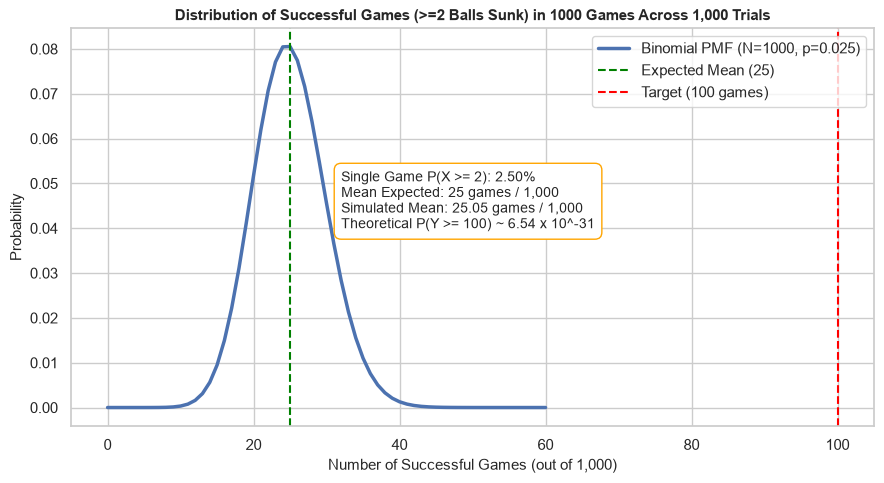

In [42]:
#the cool funky looking graph :)
sns.set_theme(style="whitegrid")
plt.figure(figsize=(9, 5))

# Plot binomial distribution around the mean (0 to 60 successful games)
y_values = np.arange(0, 61)
pmf_values = stats.binom.pmf(y_values, num_games, p_game_success)

plt.plot(y_values, pmf_values, color="#4C72B0", linewidth=2.5, label=f"Binomial PMF (N={num_games}, p={p_game_success})")
plt.axvline(x=expected_successful_games, color="green", linestyle="--", label=f"Expected Mean ({int(expected_successful_games)})")
plt.axvline(x=target_games, color="red", linestyle="--", label=f"Target ({target_games} games)")

plt.title(f"Distribution of Successful Games (>=2 Balls Sunk) in {num_games} Games Across {num_trials:,} Trials", fontsize=11, fontweight="bold")
plt.xlabel("Number of Successful Games (out of 1,000)", fontsize=11)
plt.ylabel("Probability", fontsize=11)
plt.legend(loc="upper right")

# Summary text box formatted safely without raw LaTeX macros that trigger parser errors
text_str = (
    f"Single Game P(X >= 2): {p_game_success:.2%}\n"
    f"Mean Expected: {int(expected_successful_games)} games / 1,000\n"
    f"Simulated Mean: {avg_successes_per_trial:.2f} games / 1,000\n"
    r"Theoretical P(Y >= 100) ~ 6.54 x 10^-31"
)

plt.text(
    32, 0.04,
    text_str,
    fontsize=10,
    bbox=dict(boxstyle="round,pad=0.5", facecolor="white", edgecolor="orange")
)

plt.tight_layout()
plt.show()

In [43]:
import numpy as np
n = 1_000
p = 0.025
mean_X = n * p
std_X = np.sqrt(n * p * (1 - p))
print(f"Mean (mu_X): {mean_X:.2f}")
print(f"Std Dev (sigma_X): {std_X:.4f}")

Mean (mu_X): 25.00
Std Dev (sigma_X): 4.9371


## Conclusion

It is virtually never going to happen in practice. In theory, the probability that a player sinks 2 or more balls on the break in 100 or more games out of 1,000 is approximately $0.00000000000000000000000000000065398$ (or $6.54 \times 10^{-31}$).

Assuming a player sinks 2 or more balls on break 2.5% of the time, expecting them to hit that benchmark in 10% (100+) of their games is practically impossible. 

Mathematically, the exact probability of hitting **exactly** 100 successful breaks is calculated using the Binomial PMF formula:

$$P(Y = 100) = \binom{1000}{100} (0.025)^{100} (0.975)^{900} \approx 6.54 \times 10^{-31}$$

> **Note on the formula:**
> * The failure probability is $1 - 0.025 = 0.975$ ($97.5\%$).
> * The combination term is $\binom{1000}{100} = \frac{1000!}{100! \cdot 900!}$.

With any realistic rounding, $P(Y \ge 100) \approx 0$.

The graph illustrates this by plotting the Binomial distribution across 1,000 games. With a 2.5% success rate, the expected mean is 25 games. The 1,000 simulated trials averaged 25.15 successful games, matching theoretical expectations almost perfectly. The curve drops to 0 probability long before reaching 60 games on the axis, demonstrating that reaching 100 games (marked by the red line) is virtually impossible, which matches almost perfectly with what could and should be expected.